# AIDA 2154 Final Project – 01 Image Check and Visibility Review

**Data version 2** (`shared/synthetic-data/kit-cards/`), generated from cleaned requests version 1.1.

**Question:** Are the 600 kit cards complete and consistent with their labels, how do image conditions differ across the splits, and can a reviewer identify the sampled items, including faint white hard hats?

This notebook checks the images before developing the vision pipeline. The final project explores whether a vision method can identify items shown on generated onboarding-kit cards and flag potentially missing items for coordinator review. Checking image quality and visibility first helps distinguish problems with the images from errors made by the method.

**Use of the test split.** Test images are decoded only for file-integrity and format checks in section A. Their recorded labels and image settings are included in the consistency checks and split summaries in sections A and B. Test pixels are not used for signal analysis, human visibility review, or method selection.

All cards are computer-generated and contain no personal information.

In [1]:
import hashlib
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageDraw

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
KIT = SD / "kit-cards"
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
REVIEW_DIR = Path("../review")
for folder in [OUTPUT_DIR, FIGURE_DIR, REVIEW_DIR]:
    folder.mkdir(exist_ok=True)
SEED = 2026

ITEMS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
CARD_W, CARD_H = 480, 320
HEADER_H = 36                       # coloured header band at the top of each card

# Blank cells are read as missing (NaN): in manifest.csv a blank expected value means the expectation is unknown.
# First confirm neither file contains text that pandas would also turn into missing (such as "NA" or "None"),
# so reading them with the default settings can't silently change a real value.
MISSING_LIKE_TEXT = {"NA", "N/A", "n/a", "NaN", "nan", "null", "NULL", "None", "#N/A", "<NA>", "-nan"}
as_text = {name: pd.read_csv(KIT / name, dtype=str, keep_default_na=False) for name in ["manifest.csv", "icon_instances.csv"]}
no_missing_like_text = all(not t.isin(MISSING_LIKE_TEXT).any().any() for t in as_text.values())
assert no_missing_like_text, "A label file contains text that pandas would read as missing; read it with keep_default_na=False"
manifest = pd.read_csv(KIT / "manifest.csv")
objects = pd.read_csv(KIT / "icon_instances.csv")
generation = json.loads((KIT / "outputs/generation_info.json").read_text())
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())

# The cards must have been made from the current official cleaned file
sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
cards_match_cleaning = (generation["input_sha256"] == sha(SD / "cleaning/output/requests_cleaned.csv")
                        == cleaning_info["output_sha256"]
                        and generation["input_record"]["cleaning_version"] == cleaning_info["cleaning_version"])

print(f"Data version {DATA_VERSION}; cards made from cleaning version {generation['input_record']['cleaning_version']}; "
      f"seed {generation['seed']}")
print(f"{len(manifest)} cards; {len(objects):,} drawn objects "
      f"({(objects['role'] == 'kit_item').sum():,} kit items, {(objects['role'] == 'background_object').sum()} background objects)")
print("Recorded card-generation input matches the current cleaned file:", cards_match_cleaning)
assert cards_match_cleaning, "The recorded card-generation input doesn't match the current cleaned file; rerun kit-cards/generate_kit_cards.py"

Data version 2; cards made from cleaning version 1.1; seed 2026
600 cards; 1,561 drawn objects (1,209 kit items, 352 background objects)
Recorded card-generation input matches the current cleaned file: True


## A. File and label checks (all splits)

These checks confirm that the images meet the expected file requirements and that the two label files follow the documented rules:

- Every image exists, passes Pillow's file check, opens in OpenCV, and is a 480 × 320 colour JPEG.
- There is one card per employee, with 360 training, 120 validation, and 120 test cards.
- Each item is drawn only when it is known to be expected. Every known expected item is either drawn or recorded as omitted, never both.
- The per-card counts match the object records in `icon_instances.csv`.
- Every box lies inside the card and below the header. Boxes on the same card are separated by at least 14 pixels.
- Every object record belongs to a listed card and has the same split as that card.
- Label columns contain only their allowed values. Unknown expectations have blank expected values, and those items are not drawn.

These checks establish consistency between the recorded labels. They do not independently confirm that each object appears correctly in the final image. Section B measures separation from the surrounding paper on training and validation cards, while the human review checks whether sampled items can be identified.

In [2]:
file_rows = []
for card in manifest.itertuples():
    path = KIT / "images" / card.file_name
    row = {"card_id": card.card_id, "exists": path.is_file(), "verified": False, "format": None, "mode": None,
           "width": None, "height": None, "opens_in_opencv": False, "error": ""}
    if row["exists"]:
        try:
            with Image.open(path) as img:
                img.verify()
            row["verified"] = True
            with Image.open(path) as img:
                row.update(format=img.format, mode=img.mode, width=img.width, height=img.height)
            row["opens_in_opencv"] = cv2.imread(str(path)) is not None
        except Exception as error:          # a broken file is recorded, not hidden
            row["error"] = str(error)
    file_rows.append(row)
files = pd.DataFrame(file_rows)
files_ok = (files["exists"] & files["verified"] & (files["format"] == "JPEG") & (files["mode"] == "RGB")
            & (files["width"] == CARD_W) & (files["height"] == CARD_H) & files["opens_in_opencv"])
print(f"Images that exist, open, and are 480 x 320 colour JPEGs: {int(files_ok.sum())} of {len(manifest)}")
if not files_ok.all():
    display(files[~files_ok])
assert files_ok.all() and len(files) == 600, "Some images are missing or damaged; fix them before any pixel analysis"

assert manifest["card_id"].notna().all() and manifest["card_id"].is_unique, "Card IDs are missing or repeated in the manifest"
assert objects["card_id"].isin(manifest["card_id"]).all(), "Some drawn objects belong to a card not in the manifest"
linked = objects.merge(manifest[["card_id", "split"]], on="card_id", suffixes=("_object", "_card"), validate="many_to_one")
assert linked["split_object"].eq(linked["split_card"]).all(), "Some drawn objects have a different split from their card"
card_split = manifest.set_index("card_id")["split"]
label_checks = {
    "Image file names are unique": manifest["file_name"].is_unique,
    "One card per employee": manifest["employee_id"].is_unique and manifest["card_id"].is_unique,
    "Every drawn object belongs to a listed card": objects["card_id"].isin(manifest["card_id"]).all(),
    "Every drawn object has its card's split": (objects["split"] == objects["card_id"].map(card_split)).all(),
    "Object roles, items and bands use allowed values":
        objects["role"].isin(["kit_item", "background_object"]).all()
        and objects.loc[objects["role"] == "kit_item", "object"].isin(ITEMS).all()
        and objects.loc[objects["role"] == "background_object", "object"].isin(["coffee_mug", "pen", "notebook"]).all()
        and objects["size_band"].isin(["small", "medium", "large"]).all()
        and objects["contrast_band"].isin(["low", "medium", "high"]).all(),
    "Split sizes are 360 / 120 / 120": manifest["split"].value_counts().to_dict() == {"train": 360, "validation": 120, "test": 120},
}
for item in ITEMS:
    # Blank expected values (unknown) become missing whether the file was read with blanks as "" or as NaN
    expected_numeric = pd.to_numeric(manifest[f"expected_{item}"].replace("", np.nan), errors="raise")
    known = manifest[f"expectation_known_{item}"] == 1
    expected = expected_numeric == 1
    present = manifest[f"present_{item}"] == 1
    omitted = manifest[f"omitted_{item}"] == 1
    label_checks[f"{item}: label columns use allowed values"] = (
        manifest[f"expectation_known_{item}"].isin([0, 1]).all() and manifest[f"present_{item}"].isin([0, 1]).all()
        and manifest[f"omitted_{item}"].isin([0, 1]).all() and expected_numeric.loc[known].isin([0, 1]).all())
    label_checks[f"{item}: unknown expectation has a blank expected value"] = expected_numeric.loc[~known].isna().all()
    label_checks[f"{item}: drawn only if known to be expected"] = not (present & ~(known & expected)).any()
    label_checks[f"{item}: known expected = drawn or omitted, never both"] = (
        ((known & expected) == (present | omitted)).all() and not (present & omitted).any())
    label_checks[f"{item}: unknown expectation never drawn"] = not (~known & present).any()

kit_objects = objects[objects["role"] == "kit_item"]
drawn = kit_objects.groupby(["card_id", "object"]).size().unstack(fill_value=0).reindex(
    index=manifest["card_id"], columns=ITEMS, fill_value=0)
present_table = manifest.set_index("card_id")[[f"present_{i}" for i in ITEMS]].set_axis(ITEMS, axis=1)
label_checks["Presence labels match the drawn kit items (at most one of each item per card)"] = (drawn == present_table).all().all()
counts = manifest.set_index("card_id")
label_checks["Card counts match the drawn objects"] = (
    (counts["n_present"] == drawn.sum(axis=1)).all()
    and (counts["n_background_objects"] == objects[objects["role"] == "background_object"].groupby("card_id").size()
         .reindex(counts.index, fill_value=0)).all()
    and (counts["n_omitted"] == counts[[f"omitted_{i}" for i in ITEMS]].sum(axis=1)).all())

inside = ((objects["x0"] >= 0) & (objects["y0"] >= HEADER_H) & (objects["x1"] <= CARD_W) & (objects["y1"] <= CARD_H)
          & (objects["x1"] > objects["x0"]) & (objects["y1"] > objects["y0"]))
label_checks["Every box is inside the card and below the header"] = inside.all()


def smallest_gap(card_boxes):
    # Smallest horizontal-or-vertical gap between any two boxes on a card (negative = overlap)
    b = card_boxes[["x0", "y0", "x1", "y1"]].to_numpy()
    gaps = []
    for i in range(len(b)):
        for j in range(i + 1, len(b)):
            gx = max(b[j][0] - b[i][2], b[i][0] - b[j][2])
            gy = max(b[j][1] - b[i][3], b[i][1] - b[j][3])
            gaps.append(max(gx, gy))
    return min(gaps) if gaps else np.inf


gaps = objects.groupby("card_id").apply(smallest_gap, include_groups=False)
label_checks["Boxes on a card are at least 14 pixels apart"] = (gaps >= 14).all()

label_checks = pd.Series(label_checks, name="passed")
display(label_checks.to_frame())
print(f"Smallest gap between boxes on any card: {int(gaps[np.isfinite(gaps)].min())} pixels")
assert label_checks.all(), "A file or label consistency check failed"

Images that exist, open, and are 480 x 320 colour JPEGs: 600 of 600


,passed
Image file names are unique,True
One card per employee,True
Every drawn object belongs to a listed card,True
Every drawn object has its card's split,True
"Object roles, items and bands use allowed values",True
Split sizes are 360 / 120 / 120,True
access_badge: label columns use allowed values,True
access_badge: unknown expectation has a blank expected value,True
access_badge: drawn only if known to be expected,True
"access_badge: known expected = drawn or omitted, never both",True


Smallest gap between boxes on any card: 14 pixels


## B. Image conditions across the splits

These summaries compare the generation settings recorded in `manifest.csv` and `icon_instances.csv` across training, validation, and test cards. They use metadata rather than image pixels.

The tables show differences that may affect later results, such as a higher share of small or low-contrast items in one split. Differences are documented without changing the fixed split, and test information is not used to select method settings.

In [3]:
SPLITS = ["train", "validation", "test"]
conditions = manifest.groupby("split").agg(
    cards=("card_id", "size"), blurred_cards=("blur_radius", lambda s: int((s > 0).sum())),
    median_jpeg_quality=("jpeg_quality", "median"), median_noise=("noise_sigma", "median"),
    omitted_items=("n_omitted", "sum"), background_objects=("n_background_objects", "sum")).reindex(SPLITS)
conditions["blurred_%"] = (100 * conditions["blurred_cards"] / conditions["cards"]).round(1)
conditions["median_jpeg_quality"] = conditions["median_jpeg_quality"].round(1)   # a setting, not a count; a median can end in .5
conditions["median_noise"] = conditions["median_noise"].round(2)
conditions.to_csv(OUTPUT_DIR / "image_conditions_by_split.csv")
display(conditions)

bands = [kit_objects.groupby("split").size().reindex(SPLITS).rename("kit_items")]
for band, prefix, order in [("size_band", "size", ["small", "medium", "large"]),
                            ("contrast_band", "contrast", ["low", "medium", "high"])]:
    t = pd.crosstab(kit_objects["split"], kit_objects[band]).reindex(index=SPLITS, columns=order, fill_value=0)
    shares = (100 * t.div(t.sum(axis=1), axis=0)).round(1)
    bands += [t.add_prefix(prefix + "_"), shares.add_prefix(prefix + "_").add_suffix("_%")]
item_bands = pd.concat(bands, axis=1)
item_bands.to_csv(OUTPUT_DIR / "item_size_contrast_by_split.csv")
display(item_bands)

items_by_split = pd.crosstab(kit_objects["object"], kit_objects["split"]).reindex(index=ITEMS, columns=SPLITS, fill_value=0)
items_by_split.to_csv(OUTPUT_DIR / "items_by_split.csv")
display(items_by_split)

,cards,blurred_cards,median_jpeg_quality,median_noise,omitted_items,background_objects,blurred_%
split,,,,,,,
train,360,154,77.0,3.14,128,200,42.8
validation,120,42,77.0,2.90,43,82,35.0
test,120,46,76.0,3.38,42,70,38.3


,kit_items,size_small,size_medium,size_large,size_small_%,size_medium_%,size_large_%,contrast_low,contrast_medium,contrast_high,contrast_low_%,contrast_medium_%,contrast_high_%
split,,,,,,,,,,,,,
train,720,177,278,265,24.6,38.6,36.8,175,312,233,24.3,43.3,32.4
validation,238,50,92,96,21.0,38.7,40.3,56,105,77,23.5,44.1,32.4
test,251,55,101,95,21.9,40.2,37.8,70,101,80,27.9,40.2,31.9


split,train,validation,test
object,,,
access_badge,188,65,72
safety_vest,178,55,61
hard_hat,177,62,63
laptop,88,31,28
phone,89,25,27


**Measured signal (training and validation only).** The contrast setting controls how strongly the drawing’s colours differ from the paper before lighting, noise, blur, and compression are applied. This section measures the resulting pixel differences around each kit item.

The local background colour is estimated using the median colour of a thin ring just outside the item’s box. Pixels inside the box are compared with that estimate using grayscale difference and RGB colour distance. The item’s **signal** is the 95th percentile of those differences. This summarizes stronger differences within the box, which can reflect both the drawing and image degradation.

The same measurement is taken on one empty paper patch of similar size per card, where a suitable patch can be found. The **empty-paper reference** uses two percentiles: each patch’s signal is its 95th-percentile pixel difference, and the reference is the 95th percentile across those patch signals. An item at or below this reference is flagged for comparison; it is not necessarily invisible.

Grayscale difference and RGB distance use different scales, so comparisons are made within each measure. These pixel statistics do not establish whether a person can recognise an item or how accurately a method will detect it.

Empty-paper patches found: 480 of 480 cards
Empty-paper reference (95th percentile of 480 patch signals): grayscale 6.0, colour 10.5
Median signal by item, drawing style and contrast band (training and validation):


gray_signal               colour_signal              
contrast_band              low medium   high           low medium   high
object       style                                                      
access_badge a            50.0   92.6  141.8          83.3  152.6  235.7
             b            48.6   93.4  147.3          90.5  171.4  270.6
hard_hat     a            23.2   39.8   60.6          76.0  128.8  196.3
             b            18.3   32.5   49.3          31.9   53.7   83.7
laptop       a            57.0   92.0  146.3          96.1  157.0  249.0
             b            70.2  111.7  164.7         119.2  189.9  279.2
phone        a            57.5  102.5  158.3          97.7  175.9  269.0
             b            62.1  111.2  153.5         106.0  190.2  262.3
safety_vest  a            26.5   50.1   75.1          70.9  131.2  204.9
             b            16.2   27.5   42.2          63.1  115.1  171.0

Items at or below the 95th-percentile empty-paper reference:


,items,near_empty_gray,near_empty_colour
object,,,
access_badge,253,0,0
hard_hat,239,0,0
laptop,119,0,0
phone,114,0,0
safety_vest,233,0,0


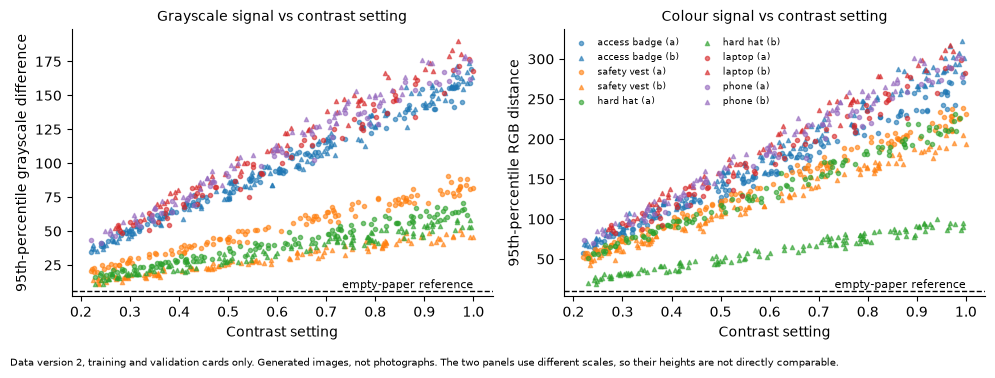

In [4]:
RING_INNER, RING_OUTER = 3, 9          # paper ring just outside a box (boxes are at least 14 px apart)
signal_rng = np.random.default_rng(SEED)   # empty-paper patches for the signal baseline only
dev_cards = manifest[manifest["split"].isin(["train", "validation"])]
dev_objects = objects[objects["split"].isin(["train", "validation"])]
images = {c: np.asarray(Image.open(KIT / "images" / f).convert("RGB"), dtype=np.float32)
          for c, f in zip(dev_cards["card_id"], dev_cards["file_name"])}


def signal(img, x0, y0, x1, y1):
    # 95th percentile difference from the surrounding paper, in grayscale and colour
    ox0, oy0 = max(x0 - RING_OUTER, 0), max(y0 - RING_OUTER, HEADER_H)
    ox1, oy1 = min(x1 + RING_OUTER, CARD_W), min(y1 + RING_OUTER, CARD_H)
    outer = img[oy0:oy1, ox0:ox1]
    keep = np.ones(outer.shape[:2], bool)
    keep[max(y0 - RING_INNER - oy0, 0):y1 + RING_INNER - oy0, max(x0 - RING_INNER - ox0, 0):x1 + RING_INNER - ox0] = False
    box = img[y0:y1, x0:x1].reshape(-1, 3)
    if not keep.any() or len(box) == 0:
        raise ValueError(f"Empty box or paper ring at {(x0, y0, x1, y1)}")
    paper = np.median(outer[keep], axis=0)
    gray = lambda rgb: rgb @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    return (float(np.percentile(np.abs(gray(box) - gray(paper[None])[0]), 95)),
            float(np.percentile(np.linalg.norm(box - paper, axis=1), 95)))


def empty_patches(card_id, n, sizes, rng):
    # Paper patches of the given sizes, at least 14 px from every object, the header and the edges
    boxes = objects.loc[objects["card_id"] == card_id, ["x0", "y0", "x1", "y1"]].values.tolist()
    found = []
    for _ in range(200):
        if len(found) == n:
            break
        w, h = sizes[rng.integers(len(sizes))]
        x0 = int(rng.integers(14, CARD_W - 14 - w)); y0 = int(rng.integers(HEADER_H + 14, CARD_H - 14 - h))
        clear = all(max(x0 - b[2], b[0] - (x0 + w), y0 - b[3], b[1] - (y0 + h)) >= 14 for b in boxes + found)
        if clear:
            found.append([x0, y0, x0 + w, y0 + h])
    return found


sizes = (dev_objects.loc[dev_objects["role"] == "kit_item", ["x1", "y1"]].to_numpy()
         - dev_objects.loc[dev_objects["role"] == "kit_item", ["x0", "y0"]].to_numpy())
rows = []
for o in dev_objects[dev_objects["role"] == "kit_item"].itertuples():
    g, c = signal(images[o.card_id], o.x0, o.y0, o.x1, o.y1)
    rows.append({"card_id": o.card_id, "split": o.split, "object": o.object, "style": o.style, "size_band": o.size_band,
                 "contrast": o.contrast, "contrast_band": o.contrast_band, "gray_signal": g, "colour_signal": c})
for card_id in dev_cards["card_id"]:
    for x0, y0, x1, y1 in empty_patches(card_id, 1, sizes, signal_rng):
        g, c = signal(images[card_id], x0, y0, x1, y1)
        rows.append({"card_id": card_id, "split": manifest.set_index("card_id").at[card_id, "split"],
                     "object": "empty paper", "style": "", "size_band": "", "contrast": np.nan, "contrast_band": "",
                     "gray_signal": g, "colour_signal": c})
signals = pd.DataFrame(rows)
signals.round(2).to_csv(OUTPUT_DIR / "item_signal_dev.csv", index=False)

empty = signals[signals["object"] == "empty paper"]
assert not empty.empty, "No empty-paper patches were found"
print(f"Empty-paper patches found: {len(empty)} of {len(dev_cards)} cards")
EMPTY_GRAY, EMPTY_COLOUR = empty["gray_signal"].quantile(0.95), empty["colour_signal"].quantile(0.95)
items_only = signals[signals["object"] != "empty paper"]
signal_summary = (items_only.groupby(["object", "style", "contrast_band"])[["gray_signal", "colour_signal"]].median()
                  .unstack("contrast_band").round(1))
signal_summary = signal_summary.reindex(columns=["low", "medium", "high"], level=1)
items_only = items_only.assign(near_empty_gray=items_only["gray_signal"] <= EMPTY_GRAY,
                               near_empty_colour=items_only["colour_signal"] <= EMPTY_COLOUR)
near_empty = items_only.groupby("object")[["near_empty_gray", "near_empty_colour"]].sum().astype(int)
near_empty.insert(0, "items", items_only.groupby("object").size())
signal_summary.to_csv(OUTPUT_DIR / "item_signal_summary_dev.csv")
near_empty.to_csv(OUTPUT_DIR / "items_near_empty_paper_dev.csv")
print(f"Empty-paper reference (95th percentile of {len(empty)} patch signals): grayscale {EMPTY_GRAY:.1f}, colour {EMPTY_COLOUR:.1f}")
print("Median signal by item, drawing style and contrast band (training and validation):")
display(signal_summary)
print("Items at or below the 95th-percentile empty-paper reference:")
display(near_empty)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, col, floor, title in [(axes[0], "gray_signal", EMPTY_GRAY, "Grayscale"), (axes[1], "colour_signal", EMPTY_COLOUR, "Colour")]:
    for item in ITEMS:
        for style, marker in [("a", "o"), ("b", "^")]:
            d = items_only[(items_only["object"] == item) & (items_only["style"] == style)]
            ax.scatter(d["contrast"], d[col], s=9, alpha=0.6, marker=marker, label=f"{item.replace('_', ' ')} ({style})",
                       color=plt.cm.tab10(ITEMS.index(item)))
    ax.axhline(floor, color="black", lw=1, ls="--")
    ax.text(1.0, floor, " empty-paper reference", va="bottom", ha="right", fontsize=8)
    ax.set_title(f"{title} signal vs contrast setting", fontsize=10)
    ax.set_xlabel("Contrast setting")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("95th-percentile grayscale difference")
axes[1].set_ylabel("95th-percentile RGB distance")
axes[1].legend(fontsize=6.5, frameon=False, loc="upper left", ncol=2)
fig.text(0.01, -0.03, "Data version 2, training and validation cards only. Generated images, not photographs. "
         "The two panels use different scales, so their heights are not directly comparable.", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "item_signal_vs_contrast.png", dpi=150, bbox_inches="tight")
plt.show()